In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:38511")
client

<Client: 'tcp://127.0.0.1:38511' processes=10 threads=40, memory=629.62 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
H = xr.open_zarr(op.join(ddir,"SW/bathy.zarr")).H

for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>

In [10]:
dsb = xr.open_zarr(op.join(ddir,"SW/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256})
dsb2z = xr.open_zarr(op.join(ddir,"SW/b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
dsb2zb = xr.open_zarr(op.join(ddir,"SW/mean/b-to-Z.zarr"))
dsu2z = xr.open_zarr(op.join(ddir,"SW/UyVx_b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
dsu2zb = xr.open_zarr(op.join(ddir,"SW/mean/UyVx_b-to-Z.zarr"))

hbar = ds.h.mean(["time"])
maskh = xr.DataArray(np.ma.masked_values(hbar,0.).mask,
                     dims=hbar.dims, 
                     coords=hbar.coords
                    ).load()
llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
cori = gsw.f(ds.y)

dsb, dsb2z, dsb2zb

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 10.88 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


(<xarray.Dataset> Size: 671MB
 Dimensions:  (level: 4, y: 2048, x: 4096)
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
 Data variables:
     hbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     ubar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     uhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     vbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     vhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>,
 <xarray.Dataset> Size: 592GB
 Dimensions:  (time: 630, y: 2048, x: 4096, Z: 7)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.0

Fitted Equation: y = 0.0105 * e^(0.2000 * x) + -0.0311


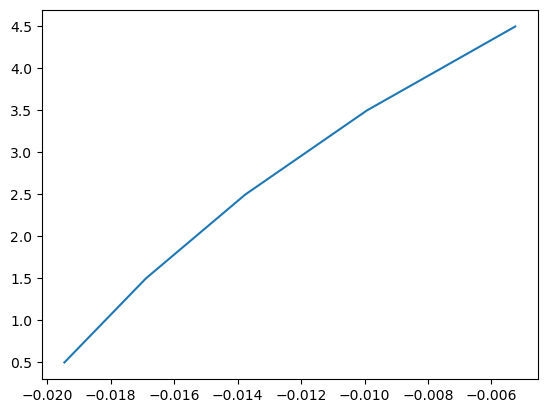

<xgcm.Grid>
X Axis (not periodic, boundary='fill'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, boundary='fill'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, boundary='fill'):
  * center   level --> right
  * right    lu --> center <xgcm.Grid>
X Axis (not periodic, boundary='fill'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, boundary='fill'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, boundary='fill'):
  * center   level


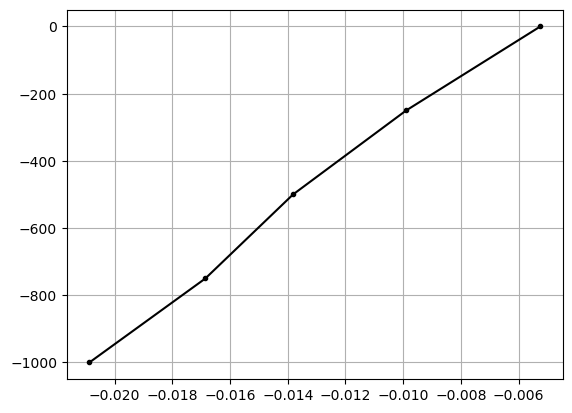

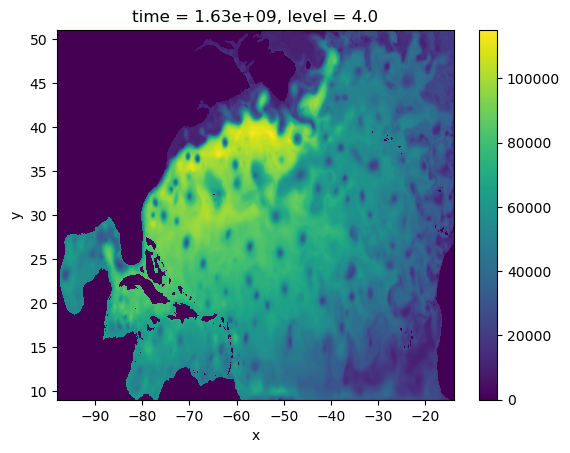

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 256.49 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


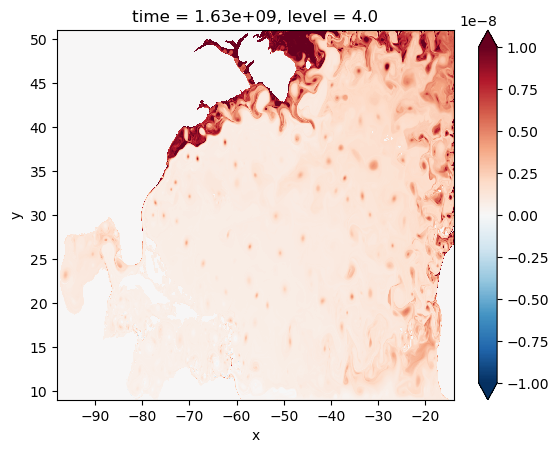

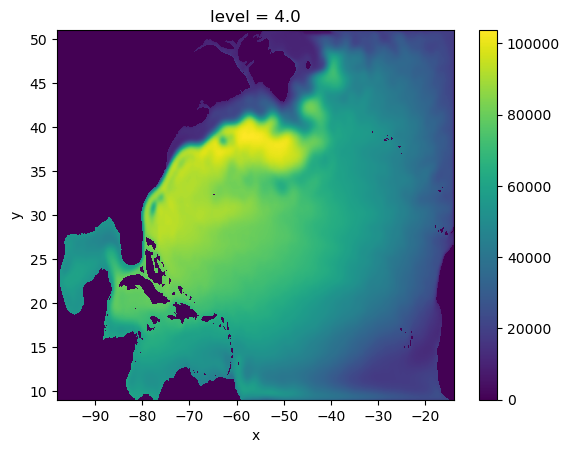

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(


(<xarray.DataArray (time: 630, level: 5, y: 2048, x: 4096)> Size: 211GB
 dask.array<rechunk-merge, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 5, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<where, shape=(4, 2048, 4096), dtype=float64, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<where, shape=(4, 2048, 4096), dtyp

In [16]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5])}
                  )

b = -9.8*(rho - rho0) / rho0

B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b[1:].lp1.values, b[1:].values, 
                       p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([0.5,1.5,2.5,3.5,4.5]))
plt.show()

bu = xr.DataArray(np.concatenate((b.data,
                    np.array([A*np.exp(B*(4.5))+C,]) 
                   )), dims="lu", 
                   coords={"lu":np.array([0.5,1.5,2.5,3.5,4.5])}
                  )

ds["b"] = bu
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))
grid = Grid(ds, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "right": "lu"}
                   })
dsb.coords["yG"] = ("yG",.5*(dsb.y.data[1:]+dsb.y.data[:-1]))
dsb.coords["xG"] = ("xG",.5*(dsb.x.data[1:]+dsb.x.data[:-1]))
gridb = Grid(dsb, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level",}
                   })
print(grid, gridb)

fig, ax = plt.subplots()
ax.plot(ds.b, -np.array([1000,750,500,250,0]), "k.-")
ax.grid(True)
plt.show()

v_x = grid.interp(grid.diff(ds["u.y"].fillna(0.).chunk({"x":-1}), 
                            "X", boundary="extend"
                           ) / xxG, 
                  "X", boundary="extend")
u_y = grid.interp(grid.diff(ds["u.x"].fillna(0.).chunk({"y":-1}), 
                            "Y", boundary="extend"
                           ) / yyG, 
                  "Y", boundary="extend")
sig = (ds.h
       / grid.diff(ds.b,"Z",boundary="extend")
      )
sig.isel(time=-1,level=-1).plot(rasterized=True)
plt.show()

Pi = (sig**-1
      * (cori + v_x - u_y)
     ).where(~maskh, 0.).chunk({"time":4,"y":128,"x":256})
Pi.isel(time=-1,level=-1).plot(vmax=1e-8, rasterized=True)
plt.show()

sigb = dsb.hbar / grid.diff(ds.b,"Z",boundary="extend")
sigb.isel(level=-1).plot(rasterized=True)
plt.show()

# vb_x = (xxG**-1 * dsb.vbar.isel(level=-1).diff("x").dropna("x").data
#        ).interp(xG=dsb.x.data).chunk({"y":128,"xG":256})
# ub_y = (yyG**-1 * dsb.ubar.isel(level=-1).diff("y").dropna("y").data
#        ).interp(yG=dsb.y.data).chunk({"yG":128,"x":256})
vb_x = gridb.interp(gridb.diff(dsb.ubar.chunk({"x":-1}), 
                             "X", boundary="extend"
                            ) / xxG, "X", boundary="extend")
ub_y = gridb.interp(gridb.diff(dsb.vbar.chunk({"y":-1}), 
                             "Y", boundary="extend"
                            ) / yyG, "Y", boundary="extend")

bPi = (sigb**-1
       * (cori + vb_x - ub_y)
      ).where(~maskh.isel(level=slice(1,None)), 0.)

Pid = Pi - bPi

# vh_x = (xxG**-1 * dsb.vhat.isel(level=-1).diff("x").dropna("x").data
#        ).interp(xG=dsb.x.data).chunk({"y":128,"xG":256})
# uh_y = (yyG**-1 * dsb.uhat.isel(level=-1).diff("y").dropna("y").data
#        ).interp(yG=dsb.y.data).chunk({"yG":128,"x":256})
vh_x = gridb.interp(gridb.diff(dsb.uhat.chunk({"x":-1}), 
                             "X", boundary="extend"
                            ) / xxG, "X", boundary="extend")
uh_y = gridb.interp(gridb.diff(dsb.vhat.chunk({"y":-1}), 
                             "Y", boundary="extend"
                            ) / yyG, "Y", boundary="extend")
Pih = (sigb**-1
       * (cori + vh_x - uh_y)
      ).where(~maskh.isel(level=slice(1,None)), 0.)

Pif = Pi - Pih

Pi, bPi, Pih

In [17]:
dsave = Pif.to_dataset(name="Piflat")
dsave["Pip"] = (Pi - Pi.mean("time")).isel(level=slice(1,None))
dsave["Pidagger"] = Pid
print(dsave)
dsave.chunk({"time":4,"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/TWA/eddyPi/InB.zarr"),
                     mode="w")

<xarray.Dataset> Size: 507GB
Dimensions:   (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level     (level) float32 16B 1.0 2.0 3.0 4.0
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    Piflat    (time, level, y, x) float64 169GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    Pip       (time, level, y, x) float64 169GB dask.array<chunksize=(4, 4, 128, 256), meta=np.ndarray>
    Pidagger  (time, level, y, x) float64 169GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 466.39 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [18]:
# dsb2z.coords["yG"] = ("yG",.5*(dsb2z.y.data[1:]+dsb2z.y.data[:-1]))
# dsb2z.coords["xG"] = ("xG",.5*(dsb2z.x.data[1:]+dsb2z.x.data[:-1]))
# dsb2zb.coords["yG"] = ("yG",.5*(dsb2z.y.data[1:]+dsb2z.y.data[:-1]))
# dsb2zb.coords["xG"] = ("xG",.5*(dsb2z.x.data[1:]+dsb2z.x.data[:-1]))

# grid = Grid(dsb2z, periodic=None, autoparse_metadata=False,
#             coords={"X": {"center": "x", "inner": "xG"},
#                     "Y": {"center": "y", "inner": "yG"},
#                     "Z": {"center": "Z"}
#                    })
# gridb = Grid(dsb2zb, periodic=None, autoparse_metadata=False,
#             coords={"X": {"center": "x", "inner": "xG"},
#                     "Y": {"center": "y", "inner": "yG"},
#                     "Z": {"center": "Z"}
#                    })
# print(grid)

# v_x = grid.interp(grid.diff(dsb2z.u.chunk({"x":-1}), 
#                             "X", boundary="extend"
#                            ) / xxG, "X", boundary="extend")
# u_y = grid.interp(grid.diff(dsb2z.v.chunk({"y":-1}), 
#                             "Y", boundary="extend"
#                            ) / yyG, "Y", boundary="extend")
Pi = (dsb2z.sig**-1
      * (cori + dsu2z.v_x - dsu2z.u_y)
     ).chunk({"time":4,"y":128,"x":256})

# vb_x = grid.interp(grid.diff(dsb2zb.ub.chunk({"x":-1}), 
#                              "X", boundary="extend"
#                             ) / xxG, "X", boundary="extend")
# ub_y = grid.interp(grid.diff(dsb2zb.vb.chunk({"y":-1}), 
#                              "Y", boundary="extend"
#                             ) / yyG, "Y", boundary="extend")
bPi = (dsb2zb.sigb**-1
       * (cori + dsu2zb.vb_x - dsu2zb.ub_y)
      ).chunk({"y":128,"x":256}) 
Pid = Pi - bPi

Pi, Pid

(<xarray.DataArray (time: 630, y: 2048, x: 4096, Z: 7)> Size: 296GB
 dask.array<mul, shape=(630, 2048, 4096, 7), dtype=float64, chunksize=(4, 128, 256, 1), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125,
 <xarray.DataArray (time: 630, y: 2048, x: 4096, Z: 7)> Size: 296GB
 dask.array<sub, shape=(630, 2048, 4096, 7), dtype=float64, chunksize=(4, 128, 256, 1), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125)

In [19]:
dsave = (Pi - Pi.mean("time",skipna=True)).to_dataset(name="Pip")
dsave["Pidagger"] = Pid
print(dsave)
dsave.chunk({"time":4,"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ_grad1st.zarr"),
                     mode="w")

<xarray.Dataset> Size: 592GB
Dimensions:   (time: 630, x: 4096, y: 2048, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 34.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [20]:
dsPiz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/b-to-Z.zarr"))
# dsz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ_grad1st.zarr"))
dsz

<xarray.Dataset> Size: 592GB
Dimensions:   (time: 630, y: 2048, x: 4096, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>

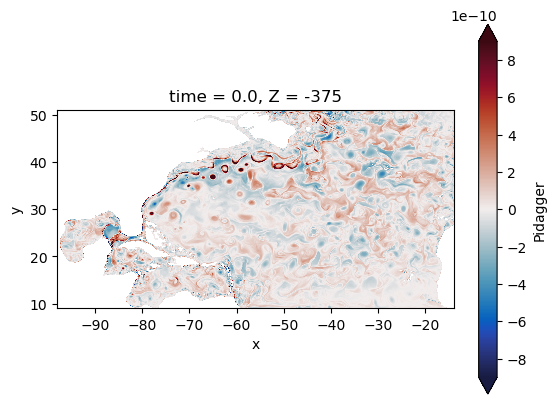

In [21]:
fig, ax = plt.subplots()
dsz.Pidagger.isel(time=0,Z=-3).plot(ax=ax, vmax=9e-10, cmap=cmocean.cm.balance, rasterized=True)
ax.set_aspect("equal")

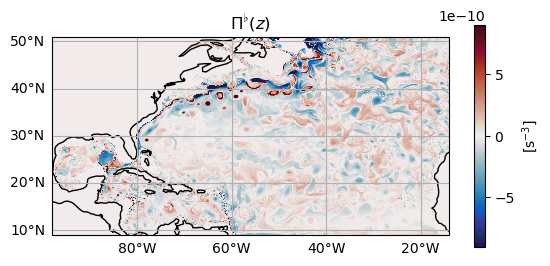

In [22]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([ds.x.min(), ds.x.max(), 
               ds.y.min(), ds.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(ds.x, ds.y, dsPiz.Piflat.isel(time=0,Z=-3), 
                   vmax=9e-10, vmin=-9e-10,
                  cmap=cmocean.cm.balance,
                  rasterized=True)

ax.set_xlabel(r"Longitude")
ax.set_ylabel(r"Latitude")
ax.set_title(r"$\Pi^\flat(z)$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^{-3}$]")
plt.savefig(op.join(ddir,"Figs/PVflat.pdf"))

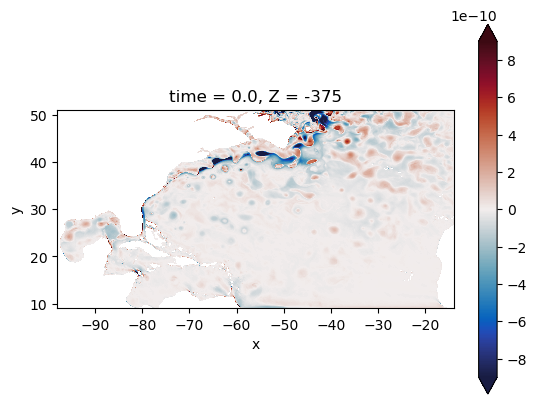

In [23]:
fig, ax = plt.subplots()
(dsPiz.Piflat - dsz.Pidagger).isel(time=0,Z=-3).plot(ax=ax, vmax=9e-10, cmap=cmocean.cm.balance, rasterized=True)
ax.set_aspect("equal")